# Day 4b: Basket mining and the simulated planogram

1. **Association rules (FP-Growth)** on Instacart orders: first by aisle, then for the top 300 products.
2. **Product metrics** for Day 6's restock priority: basket reach, reorder rate, and how strongly a product
   pulls other products into the basket.
3. **Simulated planogram** mapping shelf photos to Instacart aisles and products.

Run on the compute instance. Uses ~3 GB of memory and about 10 minutes.

**Done when:** you can explain five rules in plain business terms.

In [1]:
%pip install -q mlxtend

Note: you may need to restart the kernel to use updated packages.


## Setup

In [2]:
import glob, inspect, os, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import association_rules, fpgrowth

SRC = next(os.path.abspath(p) for p in ["../src", "src", "."] if os.path.exists(os.path.join(p, "planogram.py")))
REPO = os.path.dirname(SRC)
sys.path.insert(0, SRC)
from planogram import build_planogram, lookup

PROC = os.path.expanduser("~/data/processed/instacart")
OUT = os.path.expanduser("~/runs/day4")
os.makedirs(OUT, exist_ok=True)
SAMPLE_ORDERS = 500_000   # FP-Growth on a random sample; support estimates are within about ±0.1 points
TOP_PRODUCTS = 300

BLUE, ORANGE, VIOLET, INK = "#2a78d6", "#eb6834", "#6250d6", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK,
    "xtick.color": INK, "ytick.color": INK, "text.color": "#0b0b0b",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 11,
    "figure.dpi": 110,
})

products = pd.read_parquet(f"{PROC}/products.parquet")
prior = pd.read_parquet(f"{PROC}/order_products_prior.parquet")
print(f"{len(prior):,} order lines, {prior.order_id.nunique():,} orders, {len(products):,} products")

32,434,489 order lines, 3,214,874 orders, 49,688 products


## 1. Sample orders and build baskets
Each basket is one order. An item is "in" the basket if the order contains it.

In [3]:
rng = np.random.default_rng(0)
all_orders = prior["order_id"].unique()
sample_ids = rng.choice(all_orders, size=min(SAMPLE_ORDERS, len(all_orders)), replace=False)
sp = prior[prior.order_id.isin(sample_ids)].merge(
    products[["product_id", "product_name", "aisle_id", "aisle", "department"]], on="product_id")
orders = np.sort(sp.order_id.unique())
N = len(orders)
print(f"Sample: {N:,} orders, {len(sp):,} order lines")


def one_hot(df, item_col, names):
    """Boolean order x item table over ALL sampled orders (so support uses the right denominator)."""
    items = np.sort(df[item_col].unique())
    X = np.zeros((N, len(items)), dtype=bool)
    X[np.searchsorted(orders, df.order_id.to_numpy()), np.searchsorted(items, df[item_col].to_numpy())] = True
    return pd.DataFrame(X, columns=[names[i] for i in items])


def mine(X, min_support, max_len=3, min_lift=1.0):
    t0 = time.time()
    freq = fpgrowth(X, min_support=min_support, use_colnames=True, max_len=max_len)
    kw = {"num_itemsets": len(X)} if "num_itemsets" in inspect.signature(association_rules).parameters else {}
    rules = association_rules(freq, metric="lift", min_threshold=min_lift, **kw)
    rules["if_bought"] = rules.antecedents.map(lambda s: " + ".join(sorted(s)))
    rules["also_buys"] = rules.consequents.map(lambda s: " + ".join(sorted(s)))
    print(f"{len(freq):,} frequent itemsets, {len(rules):,} rules in {time.time() - t0:.0f}s")
    return freq, rules[["if_bought", "also_buys", "support", "confidence", "lift",
                        "antecedents", "consequents"]].sort_values("lift", ascending=False)

/anaconda/envs/azureml_py38/lib/python3.10/site-packages/pandas/core/algorithms.py:522: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  common = np.find_common_type([values.dtype, comps_array.dtype], [])


Sample: 500,000 orders, 5,039,808 order lines


## 2. Aisle-level rules
- **Support:** share of all orders containing both sides.
- **Confidence:** of the orders with the "if bought" side, the share that also contain the other side.
- **Lift:** how much more likely the pair is than chance. 1.0 = unrelated; 2.0 = twice as likely as chance.
  Lift matters most here, because very common aisles (fresh fruit) get high confidence with almost anything.

In [4]:
aisle_names = products.drop_duplicates("aisle_id").set_index("aisle_id")["aisle"]
Xa = one_hot(sp[["order_id", "aisle_id"]].drop_duplicates(), "aisle_id", aisle_names)
freq_a, rules_a = mine(Xa, min_support=0.02, max_len=3, min_lift=1.2)

show = rules_a[(rules_a.confidence >= 0.2)].head(15)
show[["if_bought", "also_buys", "support", "confidence", "lift"]].round(3)

718 frequent itemsets, 2,204 rules in 1093s


,if_bought,also_buys,support,confidence,lift
1236,chips pretzels + fresh fruits,fresh dips tapenades,0.025,0.238,2.437
1241,fresh dips tapenades,chips pretzels + fresh fruits,0.025,0.256,2.437
1340,dry pasta,fresh vegetables + packaged cheese,0.022,0.309,2.296
1299,canned jarred vegetables,fresh vegetables + packaged cheese,0.022,0.304,2.261
1541,lunch meat + yogurt,packaged cheese,0.020,0.506,2.206
1540,packaged cheese + yogurt,lunch meat,0.020,0.228,2.187
1555,lunch meat,packaged cheese + packaged vegetables fruits,0.026,0.247,2.184
1554,packaged cheese + packaged vegetables fruits,lunch meat,0.026,0.228,2.184
1517,bread + fresh fruits,lunch meat,0.025,0.227,2.173
1520,lunch meat,bread + fresh fruits,0.025,0.243,2.173


## 3. Product-level rules (top 300 products)

In [5]:
counts = sp.product_id.value_counts()
top_ids = counts.head(TOP_PRODUCTS).index
name_of = products.set_index("product_id")["product_name"]
Xp = one_hot(sp.loc[sp.product_id.isin(top_ids), ["order_id", "product_id"]], "product_id", name_of)
freq_p, rules_p = mine(Xp, min_support=0.002, max_len=3, min_lift=1.0)

strong = rules_p[(rules_p.lift >= 1.5) & (rules_p.support >= 0.002)]
print(f"{len(strong):,} rules with lift >= 1.5")
strong.head(20)[["if_bought", "also_buys", "support", "confidence", "lift"]].round(3)

/anaconda/envs/azureml_py38/lib/python3.10/site-packages/pandas/core/algorithms.py:522: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  common = np.find_common_type([values.dtype, comps_array.dtype], [])


886 frequent itemsets, 1,250 rules in 993s
1,054 rules with lift >= 1.5


,if_bought,also_buys,support,confidence,lift
1175,Icelandic Style Skyr Blueberry Non-fat Yogurt,Non Fat Raspberry Yogurt,0.002,0.372,74.184
1174,Non Fat Raspberry Yogurt,Icelandic Style Skyr Blueberry Non-fat Yogurt,0.002,0.443,74.184
1216,Vanilla Skyr Nonfat Yogurt,Icelandic Style Skyr Blueberry Non-fat Yogurt,0.002,0.366,61.342
1217,Icelandic Style Skyr Blueberry Non-fat Yogurt,Vanilla Skyr Nonfat Yogurt,0.002,0.345,61.342
1020,Total 2% with Strawberry Lowfat Greek Strained...,Total 2% Lowfat Greek Strained Yogurt With Blu...,0.003,0.302,47.892
1021,Total 2% Lowfat Greek Strained Yogurt With Blu...,Total 2% with Strawberry Lowfat Greek Strained...,0.003,0.441,47.892
1019,Total 2% with Strawberry Lowfat Greek Strained...,Total 2% Lowfat Greek Strained Yogurt with Peach,0.003,0.272,43.110
1018,Total 2% Lowfat Greek Strained Yogurt with Peach,Total 2% with Strawberry Lowfat Greek Strained...,0.003,0.397,43.110
1159,Yellow Bell Pepper,Orange Bell Pepper,0.002,0.291,23.516
1158,Orange Bell Pepper,Yellow Bell Pepper,0.002,0.185,23.516


### Rules in plain English
A helper to draft sentences. Edit them into your own words for the README.

In [6]:
def sentence(r):
    return (f"Shoppers who buy {r.if_bought} are {r.lift:.1f}x more likely than average to also buy "
            f"{r.also_buys} ({r.confidence:.0%} of those baskets do; {r.support:.1%} of all orders).")


picks = pd.concat([rules_a[rules_a.confidence >= 0.2].head(3),
                   strong[strong.antecedents.map(len) == 1].head(4),
                   strong[strong.antecedents.map(len) == 2].head(2)])
for r in picks.itertuples():
    print("-", sentence(r))

- Shoppers who buy chips pretzels + fresh fruits are 2.4x more likely than average to also buy fresh dips tapenades (24% of those baskets do; 2.5% of all orders).
- Shoppers who buy fresh dips tapenades are 2.4x more likely than average to also buy chips pretzels + fresh fruits (26% of those baskets do; 2.5% of all orders).
- Shoppers who buy dry pasta are 2.3x more likely than average to also buy fresh vegetables + packaged cheese (31% of those baskets do; 2.2% of all orders).
- Shoppers who buy Icelandic Style Skyr Blueberry Non-fat Yogurt are 74.2x more likely than average to also buy Non Fat Raspberry Yogurt (37% of those baskets do; 0.2% of all orders).
- Shoppers who buy Non Fat Raspberry Yogurt are 74.2x more likely than average to also buy Icelandic Style Skyr Blueberry Non-fat Yogurt (44% of those baskets do; 0.2% of all orders).
- Shoppers who buy Vanilla Skyr Nonfat Yogurt are 61.3x more likely than average to also buy Icelandic Style Skyr Blueberry Non-fat Yogurt (37% of th

### Five rules in business terms (write these yourself)
| # | Rule | Lift | What it means | What a store could do |
|---|---|---|---|---|
| 1 | … | … | … | e.g. place together / cross-promote / check both when one is out of stock |
| 2 | … | … | … | … |
| 3 | … | … | … | … |
| 4 | … | … | … | … |
| 5 | … | … | … | … |

Tip: a high-lift pair is also a **restock risk pair**. If one is out of stock, the basket that would have
included both may go to a competitor, which is the point of Day 6's priority score.

## 4. Product metrics for the restock priority
- **Basket reach:** share of orders containing the product.
- **Reorder rate:** share of its purchases that are repeat purchases (habit products hurt most when missing).
- **Pull:** number of other top products it lifts by at least 1.5x, and its strongest partner.
  Products outside the top 300 get pull = 0 (a known limitation).

In [7]:
pm = (sp.groupby("product_id").agg(orders=("order_id", "size"), reorder_rate=("reordered", "mean"))
      .join(products.set_index("product_id")[["product_name", "aisle_id", "aisle", "department"]]))
pm["reach"] = pm.orders / N

pairs = rules_p[(rules_p.antecedents.map(len) == 1) & (rules_p.consequents.map(len) == 1) & (rules_p.lift >= 1.5)].copy()
pairs["a"] = pairs.antecedents.map(lambda s: next(iter(s)))
pairs["b"] = pairs.consequents.map(lambda s: next(iter(s)))
pull = pairs.groupby("a").agg(pull_partners=("b", "nunique"), max_lift=("lift", "max"))
best = pairs.sort_values("lift", ascending=False).drop_duplicates("a").set_index("a")["b"].rename("top_partner")
pm = pm.join(pull.join(best), on="product_name")
pm[["pull_partners", "max_lift"]] = pm[["pull_partners", "max_lift"]].fillna(0)
pm = pm.reset_index().sort_values("reach", ascending=False)
pm.to_parquet(f"{OUT}/product_metrics.parquet", index=False)

print(f"Reach: median {pm.reach.median():.4%}, top product {pm.reach.max():.1%}")
pm.head(10)[["product_name", "aisle", "reach", "reorder_rate", "pull_partners", "top_partner", "max_lift"]].round(3)

Reach: median 0.0022%, top product 14.7%


,product_name,aisle,reach,reorder_rate,pull_partners,top_partner,max_lift
23008,Banana,fresh fruits,0.147,0.845,59.0,Bartlett Pears,2.650
12173,Bag of Organic Bananas,fresh fruits,0.118,0.832,62.0,Organic Navel Orange,2.784
19565,Organic Strawberries,fresh fruits,0.081,0.780,55.0,Organic Yellow Peaches,4.156
20277,Organic Baby Spinach,packaged vegetables fruits,0.075,0.772,56.0,Frozen Organic Wild Blueberries,3.072
43692,Organic Hass Avocado,fresh fruits,0.066,0.798,46.0,Organic Lemon,3.590
44211,Organic Avocado,fresh fruits,0.055,0.761,38.0,Broccoli Crown,3.353
44081,Large Lemon,fresh fruits,0.048,0.696,30.0,Limes,4.176
15541,Strawberries,fresh fruits,0.044,0.697,11.0,Raspberries,4.684
24264,Limes,fresh fruits,0.044,0.682,32.0,Bunched Cilantro,6.353
25774,Organic Whole Milk,milk,0.043,0.832,14.0,Organic Whole String Cheese,3.437


/anaconda/envs/azureml_py38/lib/python3.10/site-packages/IPython/core/pylabtools.py:77: DeprecationWarning: backend2gui is deprecated since IPython 8.24, backends are managed in matplotlib and can be externally registered.
  warnings.warn(
/anaconda/envs/azureml_py38/lib/python3.10/site-packages/IPython/core/pylabtools.py:77: DeprecationWarning: backend2gui is deprecated since IPython 8.24, backends are managed in matplotlib and can be externally registered.
  warnings.warn(
/anaconda/envs/azureml_py38/lib/python3.10/site-packages/IPython/core/pylabtools.py:77: DeprecationWarning: backend2gui is deprecated since IPython 8.24, backends are managed in matplotlib and can be externally registered.
  warnings.warn(


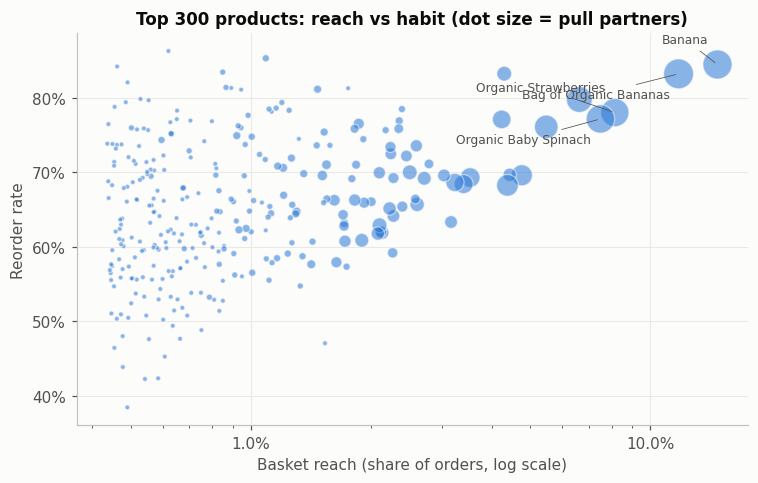

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
top = pm.head(300)
ax.scatter(top.reach, top.reorder_rate, s=10 + 6 * top.pull_partners, color=BLUE, alpha=0.55,
           edgecolor="#fcfcfb", linewidth=0.8)
for k, r in enumerate(top.head(4).itertuples()):  # label the 4 biggest, staggered to avoid overlap
    ax.annotate(r.product_name, (r.reach, r.reorder_rate), fontsize=8, color=INK, ha="right",
                xytext=(-6, 14 if k % 2 == 0 else -16), textcoords="offset points",
                arrowprops=dict(arrowstyle="-", color=INK, linewidth=0.5))
ax.set_xscale("log")
ax.set(xlabel="Basket reach (share of orders, log scale)", ylabel="Reorder rate",
       title="Top 300 products: reach vs habit (dot size = pull partners)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.savefig(f"{OUT}/product_metrics.png", bbox_inches="tight"); plt.show()

## 5. Simulated planogram
SKU-110K photos have no product names, so each photo is treated as one shelf bay assigned to an Instacart aisle,
with that aisle's best sellers at eye level. See `src/planogram.py`. **This is simulated**: a real retailer would
supply its planogram. Say so in the README.

In [9]:
plan = build_planogram(pm, n_aisles=60, n_shelves=8, n_positions=5)
os.makedirs(f"{REPO}/config", exist_ok=True)
plan.to_csv(f"{REPO}/config/planogram.csv", index=False)  # small, deterministic: commit it
print(f"{plan.aisle_slot.nunique()} aisles x {plan.shelf.nunique()} shelves x {plan.position.nunique()} positions "
      f"= {len(plan):,} slots, {plan.product_id.nunique():,} distinct products")
plan[plan.aisle_slot == 0].pivot(index="shelf", columns="position", values="product_name")

/anaconda/envs/azureml_py38/lib/python3.10/site-packages/pandas/core/dtypes/cast.py:1641: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  return np.find_common_type(types, [])
/anaconda/envs/azureml_py38/lib/python3.10/site-packages/pandas/core/dtypes/cast.py:1641: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  return np.find_common_type(types, [])
/anaconda/envs/azureml_py38/lib/python3.10/site-packages/pandas/core/dtypes/cast.py:1641: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Depr

position,0,1,2,3,4
shelf,,,,,
0,Cantaloupe,Blackberries,Organic Yellow Peaches,Organic Bosc Pear,Large Grapefruit
1,Organic Granny Smith Apple,Organic Kiwi,Small Hass Avocado,Organic D'Anjou Pears,Organic Navel Orange
2,Large Lemon,Strawberries,Limes,Organic Fuji Apple,Organic Lemon
3,Banana,Bag of Organic Bananas,Organic Strawberries,Organic Hass Avocado,Organic Avocado
4,Apple Honeycrisp Organic,Honeycrisp Apple,Organic Large Extra Fancy Fuji Apple,Organic Gala Apples,Organic Blackberries
5,Grape White/Green Seedless,Organic Bartlett Pear,Granny Smith Apples,Bartlett Pears,Gala Apples
6,Organic Banana,Large Yellow Flesh Nectarine,Bing Cherries,Seedless Small Watermelon,Honeycrisp Apples
7,Organic Red Delicious Apple,Organic Nectarine,Organic Cripps Pink Apples,Apples,Blood Oranges


### Preview of Day 6: what is missing in Day 3's gaps?
Each gap's shelf row and horizontal position are looked up in the planogram.

In [10]:
try:
    g3 = pd.read_parquet(os.path.expanduser("~/runs/day3/gaps.parquet"))
    sz3 = pd.read_parquet(os.path.expanduser("~/runs/day3/image_sizes.parquet")).set_index("image")
    demo = g3.sample(min(8, len(g3)), random_state=0).copy()
    looked = [lookup(plan, r.image, r.row, ((r.x1 + r.x2) / 2) / sz3.loc[r.image, "w"]) for r in demo.itertuples()]
    demo["product_id"] = [int(p.product_id) for p in looked]
    demo = demo.merge(pm[["product_id", "product_name", "aisle", "reach", "reorder_rate", "top_partner"]],
                      on="product_id", how="left")
    display(demo[["image", "row", "product_name", "aisle", "reach", "reorder_rate", "top_partner"]].round(3))
except FileNotFoundError:
    print("Day 3 gap results not found in ~/runs/day3; skip this preview.")

/anaconda/envs/azureml_py38/lib/python3.10/site-packages/pandas/core/dtypes/cast.py:1641: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  return np.find_common_type(types, [])
/anaconda/envs/azureml_py38/lib/python3.10/site-packages/pandas/core/dtypes/cast.py:1641: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  return np.find_common_type(types, [])
/anaconda/envs/azureml_py38/lib/python3.10/site-packages/pandas/core/dtypes/cast.py:1641: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Depr

,image,row,product_name,aisle,reach,reorder_rate,top_partner
0,test_2161.jpg,7,Organic Reduced Fat Omega-3 Milk,milk,0.002,0.842,NaN
1,test_677.jpg,14,Cheese Puffs,chips pretzels,0.001,0.591,NaN
2,test_2131.jpg,1,Kale & Spinach Superfood Puffs,baby food formula,0.001,0.513,NaN
3,test_2411.jpg,2,Pure Sparkling Water,water seltzer sparkling water,0.009,0.813,NaN
4,test_2266.jpg,9,Gluten Free Organic Soyrizo,tofu meat alternatives,0.000,0.527,NaN
5,test_2023.jpg,2,Creamy Deluxe Shells & Real Aged Cheddar Sauce,instant foods,0.001,0.602,NaN
6,test_1074.jpg,1,Marcona Almonds,nuts seeds dried fruit,0.001,0.521,NaN
7,test_283.jpg,19,Organic Z Mixed Berry Fruit Rope,energy granola bars,0.001,0.644,NaN


## 6. Save

In [11]:
for name, df in [("aisle_rules", rules_a), ("product_rules", rules_p)]:
    df.drop(columns=["antecedents", "consequents"]).to_parquet(f"{OUT}/{name}.parquet", index=False)
print(sorted(os.listdir(OUT)))

['aisle_rules.parquet', 'label_images', 'label_preds.parquet', 'product_metrics.parquet', 'product_metrics.png', 'product_rules.parquet']


Back up and commit (terminal):
```bash
azcopy copy "$HOME/runs/day4" "https://stretail26561.blob.core.windows.net/retail-data/outputs/" --recursive
```
Commit `src/planogram.py`, `config/planogram.csv`, this notebook and `labels/gap_labels_day4.json`.